In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.fft import fft2, ifft2, fftshift

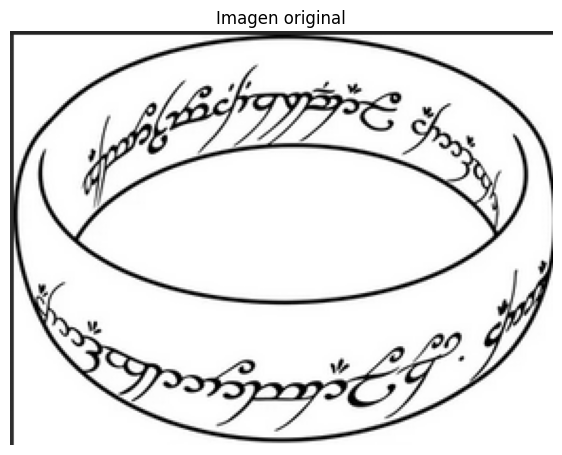

In [8]:
img = Image.open("imagen_ft.png").convert("L")
img = img.copy()
img.thumbnail((512, 512), Image.Resampling.LANCZOS)
image = np.asarray(img, dtype=float)
plt.figure(figsize=(7, 7))
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title(f"Imagen original")
plt.axis("off")
plt.show()

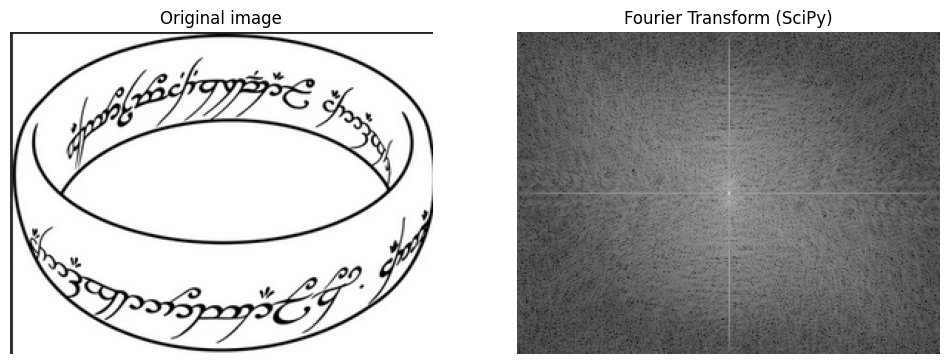

In [9]:
#Punto  1 FFT
F_scipy = fft2(image)
F_shifted = fftshift(F_scipy)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(np.log1p(np.abs(F_shifted)), cmap="gray")
plt.title("Fourier Transform (SciPy)")
plt.axis("off")

plt.show()

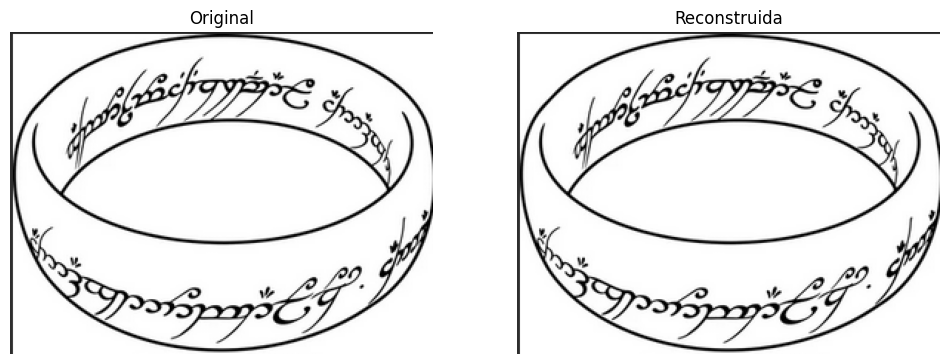

Mean Squared Error: 7.25e-27


In [12]:
#Punto 3 FFt inversa
image_reconstructed = ifft2(F_scipy).real
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(image_reconstructed, cmap="gray")
plt.title("Reconstruida")
plt.axis("off")
plt.show()
mse = np.mean((image - image_reconstructed)**2)
print(f"Mean Squared Error: {mse:.2e}")

In [15]:
def FT(x, y):
    N = len(y)
    k = np.arange(N)
    W = np.exp(-2j * np.pi * np.outer(k, x) / N)
    return W @ y
def FT2(image):
    M, N = image.shape
    F_rows = np.array([FT(np.arange(N), row)for row in image])
    F_2d = np.array([FT(np.arange(M), col)for col in F_rows.T]).T
    return F_2d

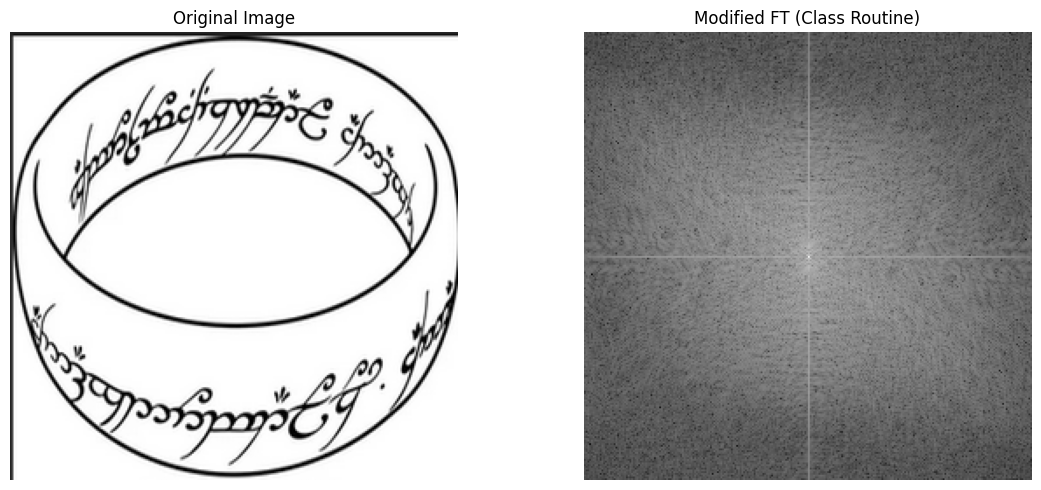

In [18]:
#Punto 2
img_large = img.resize((256, 256), Image.Resampling.LANCZOS)
image_large = np.asarray(img_large, dtype=float)
F_manual = FT2(image_large)
F_manual_shifted = fftshift(F_manual)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_large, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(np.log1p(np.abs(F_manual_shifted)), cmap="gray")
plt.title("Modified FT (Class Routine)")
plt.axis("off")
plt.tight_layout()
plt.show()

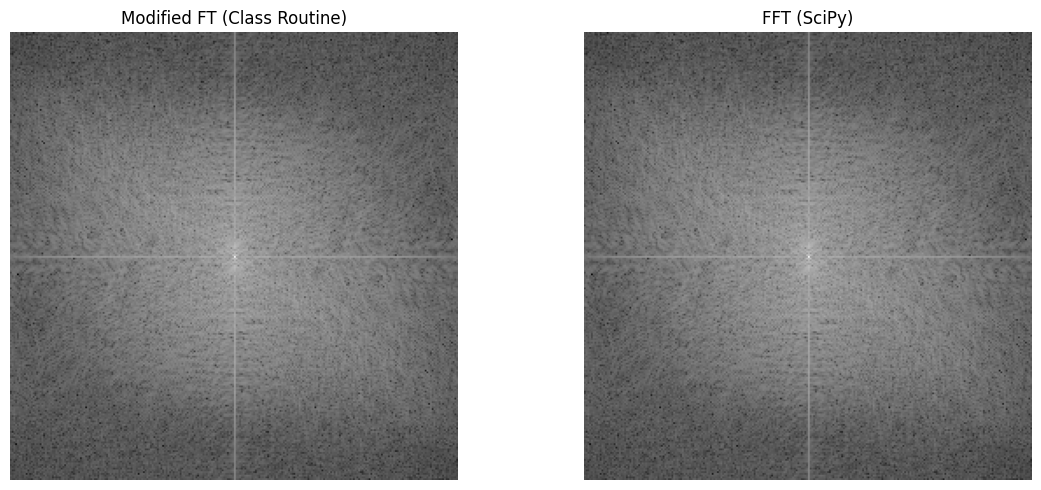

Maximum absolute error: 1.70e-07
Relative error: 4.36e-14
Same results: True


In [19]:
# FFT y Ft comparacion
F_scipy_small = fft2(image_large)
F_manual_shifted = fftshift(F_manual)
F_scipy_shifted = fftshift(F_scipy_small)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.log1p(np.abs(F_manual_shifted)), cmap="gray")
plt.title("Modified FT (Class Routine)")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(np.log1p(np.abs(F_scipy_shifted)), cmap="gray")
plt.title("FFT (SciPy)")
plt.axis("off")
plt.tight_layout()
plt.show()
max_error = np.max(np.abs(F_manual - F_scipy_small))
relative_error = (
    np.linalg.norm(F_manual - F_scipy_small)
    / np.linalg.norm(F_scipy_small)
)
print(f"Maximum absolute error: {max_error:.2e}")
print(f"Relative error: {relative_error:.2e}")
print("Same results:", np.allclose(F_manual, F_scipy_small, rtol=1e-10, atol=1e-8))

In [22]:
#Puno 3
# Inversa
def IFT(x, y):
    N = len(y)
    n = np.arange(N)
    W_inv = np.exp(2j * np.pi * np.outer(n, x) / N)
    return (W_inv @ y) / N
def IFT2(F):
    M, N = F.shape
    f_rows = np.array([IFT(np.arange(N), row)for row in F])
    f_2d = np.array([IFT(np.arange(M), col)for col in f_rows.T]).T
    return f_2d

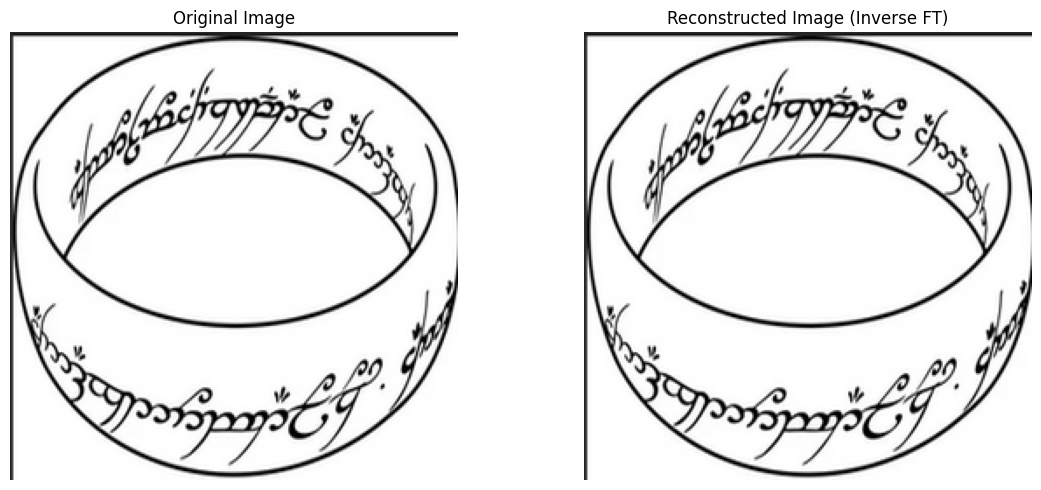

Mean Squared Error: 5.18e-23
Maximum Reconstruction Error: 2.83e-11


In [24]:
# Inversa
image_reconstructed_manual = IFT2(F_manual).real
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_large, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(image_reconstructed_manual, cmap="gray", vmin=0, vmax=255)
plt.title("Reconstructed Image (Inverse FT)")
plt.axis("off")
plt.tight_layout()
plt.show()
mse = np.mean((image_large - image_reconstructed_manual)**2)
max_error = np.max(np.abs(image_large - image_reconstructed_manual))
print(f"Mean Squared Error: {mse:.2e}")
print(f"Maximum Reconstruction Error: {max_error:.2e}")

In [ ]:
#Sí se obtuvo la misma imagen, el error es muy pequeño